In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from shared import (CODED_CSV, THEME_TABLE_CSV, THEMES, NATIVE, NEUTRAL, NEGATIVE,
                    GRID, labels_for, save)

In [ ]:
df = pd.read_csv(CODED_CSV, parse_dates=["date"])
nat = df[df["brand"] == "Native"].copy()
len(nat)

627

In [ ]:
rows = []
for theme in THEMES:
    sub = nat[nat[theme] == 1]
    if len(sub) == 0:
        continue
    rows.append({
        "theme": theme,
        "n": len(sub),
        "pct_of_reviews": len(sub) / len(nat) * 100,
        "mean_vader": sub["vader"].mean(),
    })

nat_table = pd.DataFrame(rows)
nat_table.sort_values("pct_of_reviews", ascending=False)

,theme,n,pct_of_reviews,mean_vader
2,scent,250,39.872408,0.343086
1,efficacy,197,31.419458,0.237746
5,ingredients,157,25.039872,0.355016
3,transition,72,11.483254,0.313422
0,irritation,68,10.845295,0.102850
4,price_value,46,7.336523,0.168809
6,ownership_trust,13,2.073365,0.211631
7,packaging,13,2.073365,0.388338


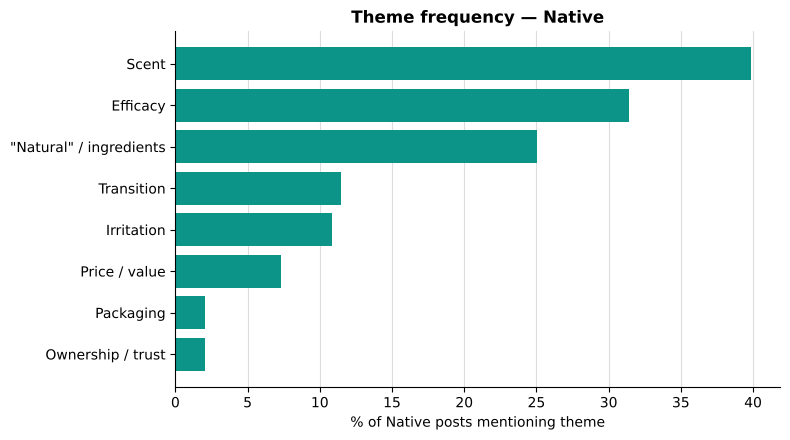

In [ ]:
data = nat_table.sort_values("pct_of_reviews")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(labels_for(data["theme"]), data["pct_of_reviews"], color=NATIVE)
ax.set_xlabel("% of Native posts mentioning theme")
ax.set_title("Theme frequency — Native", fontweight="bold")
ax.xaxis.grid(True, color=GRID, lw=0.8)
ax.set_axisbelow(True)
save(fig, "theme_frequency.png")

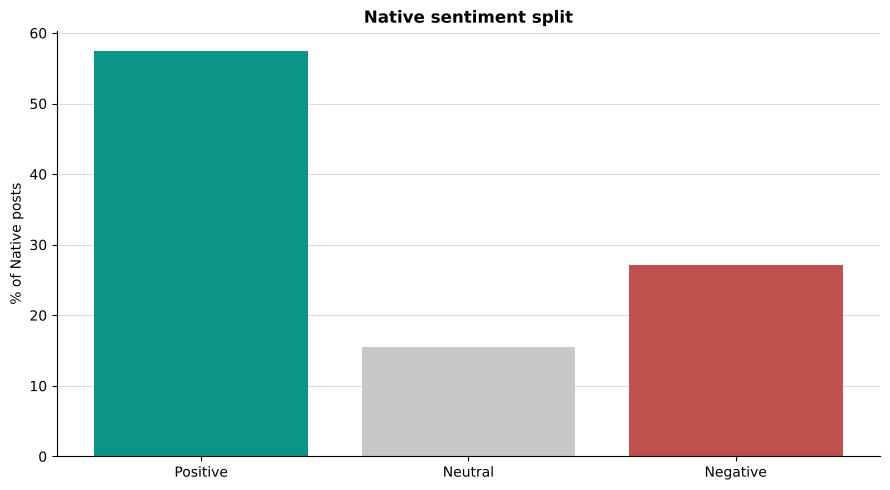

In [ ]:
share = nat["sentiment"].value_counts(normalize=True) * 100
cats = ["positive", "neutral", "negative"]

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(["Positive", "Neutral", "Negative"],
       [share.get(c, 0) for c in cats],
       color=[NATIVE, NEUTRAL, NEGATIVE])
ax.set_ylabel("% of Native posts")
ax.set_title("Native sentiment split", fontweight="bold")
ax.yaxis.grid(True, color=GRID, lw=0.8)
ax.set_axisbelow(True)
save(fig, "sentiment_split.png")

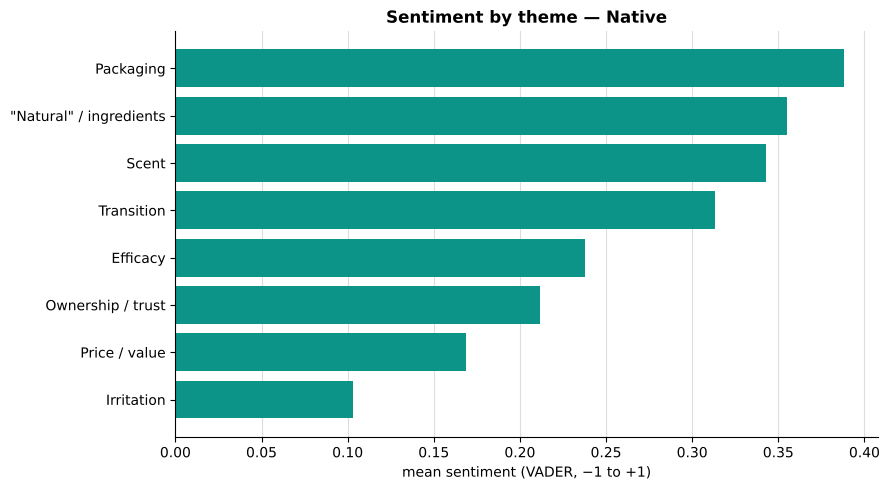

In [ ]:
data = nat_table.sort_values("mean_vader")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(labels_for(data["theme"]), data["mean_vader"], color=NATIVE)
ax.set_xlabel("mean sentiment (VADER, −1 to +1)")
ax.set_title("Sentiment by theme — Native", fontweight="bold")
ax.xaxis.grid(True, color=GRID, lw=0.8)
ax.set_axisbelow(True)
save(fig, "sentiment_by_theme.png")

In [ ]:
nat_table.to_csv(THEME_TABLE_CSV, index=False)